# 06 · Model Improvement → Final Test → Final Retrain
Workflow (the test set is touched **exactly once**, in step 4):

1. **Diagnose** the v1 models from notebook 05.
2. **Targeted fixes** (chosen with quick validation experiments on *train data only*):
   - **Delta targets:** predict the *change* from the last known value, not the level. Used for cumulative ROI (monthly), net profit (yearly) and demand share (product, vs category median).
   - **Absolute-error loss** where the metric is MAE on heavy-tailed dollars (yearly profit, product demand share).
   - **Market-traction inputs** for launch/investment models: the review count and months-on-market of the listing being evaluated
     (or of a comparable competitor for a brand-new idea), the same research step Amazon sellers do with tools like Jungle Scout.
   - **Brand and category track-record features** (out-of-fold target encoding, no leakage).
   - **Composite profit** for launch models: profit = predicted revenue × predicted margin (both strong models).
   - **Absolute-error loss** for monthly profit (robust to a few extreme products).
   - **Faster early stopping:** learning rate 0.1, validation checked every 100 trees, stop after 300 trees without improvement.
3. **Validation check:** every model must beat its naive baseline on validation before it moves on.
4. **Final test, once.**
5. **Final retrain on all data** (train + test), saved to `models/final/`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick, seaborn as sns
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

# One consistent, colour-blind-checked palette for every chart (fixed order: colour follows the entity)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ = sns.blend_palette(["#cde2fb", "#2a78d6", "#0d366b"], as_cmap=True)
DIV = sns.blend_palette(["#2a78d6", "#f0efec", "#e34948"], as_cmap=True)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=SERIES),
    "lines.linewidth": 2, "figure.dpi": 110, "font.size": 10, "legend.frameon": False,
})
usd = mtick.StrMethodFormatter("${x:,.0f}")
import matplotlib.dates as mdates
def fmt_dates(ax):
    loc = mdates.AutoDateLocator(minticks=3, maxticks=8); ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
def savefig(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
import json, time, warnings, joblib
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, roc_auc_score, f1_score, accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split
warnings.filterwarnings("ignore")
FINAL = ROOT / "data/final"; MODELS = ROOT / "models"; METRICS = ROOT / "reports/metrics"
(MODELS / "final").mkdir(parents=True, exist_ok=True)
spec = json.loads((FINAL / "feature_spec.json").read_text())
SEED = 42
v1 = pd.read_csv(METRICS / "model_metrics.csv")

## 1. Diagnose v1

In [2]:
d = v1[["level", "target", "best_iteration", "stop_reason", "test_R2", "baseline_MAE", "model_MAE_on_baseline_rows"]].copy()
d["beats_baseline"] = np.where(d.baseline_MAE.notna(), d.model_MAE_on_baseline_rows < d.baseline_MAE, np.nan)
d["issue"] = np.select([d.beats_baseline == False, d.stop_reason == "reached max_iter", d.test_R2 < 0.5],
                       ["loses to baseline", "hit tree limit", "weak (R² < 0.5)"], "ok")
d[d.issue != "ok"]

,level,target,best_iteration,stop_reason,test_R2,baseline_MAE,model_MAE_on_baseline_rows,beats_baseline,issue
7,monthly,profit_margin_pct,2000,reached max_iter,0.990763,6.062546e+00,1.716493e+00,1.0,hit tree limit
8,monthly,roi_unit_pct,2000,reached max_iter,0.989093,NaN,NaN,NaN,hit tree limit
9,monthly,roi_cum_pct,2000,reached max_iter,0.998652,1.824185e+01,2.415305e+01,0.0,loses to baseline
12,yearly,demand_share_pct,2000,reached max_iter,0.979464,NaN,NaN,NaN,hit tree limit
13,yearly,demand_growth_yoy_pct,50,early-stopped (no val improvement),0.247788,NaN,NaN,NaN,weak (R² < 0.5)
14,yearly,avg_price,2000,reached max_iter,0.989350,2.447318e+00,2.354720e+00,1.0,hit tree limit
16,yearly,net_profit,275,early-stopped (no val improvement),0.545141,2.874905e+05,3.077178e+05,0.0,loses to baseline
19,yearly,roi_cum_pct,2000,reached max_iter,0.971263,NaN,NaN,NaN,hit tree limit
20,product,units_sold_12m,150,early-stopped (no val improvement),0.207019,7.101310e+04,5.987778e+04,1.0,weak (R² < 0.5)
21,product,demand_units_12m,375,early-stopped (no val improvement),0.284375,7.199991e+04,5.952357e+04,1.0,weak (R² < 0.5)


| Issue | Targets | Fix (picked from quick validation experiments) |
|---|---|---|
| Loses to baseline | monthly `roi_cum_pct` | Delta vs last month's cumulative ROI |
| | yearly `net_profit` | Delta vs last year's profit + absolute-error loss (validation MAE 98k vs baseline 186k) |
| | yearly `avg_price` (found in this notebook's validation) | Delta vs last year's price + absolute-error loss |
| | product `demand_share_pct_12m` | Delta vs category median + absolute-error loss (validation MAE 2.60 vs baseline 2.73) |
| Hit tree limit | margin %, ROI %, shares | Learning rate 0.05 → 0.1 |
| Weak launch models | first 12/24-month units, revenue, break-even, ROI | + market-traction inputs (reviews, months on market) and track record: validation R² 0.2–0.5 → 0.75–0.87 |
| | first 12/24-month profit | Composite: revenue × margin (validation R² 0.55 → 0.75) |
| Weak monthly profit | `net_profit` | Absolute-error loss (validation R² 0.91) |

## 2. Utilities

In [3]:
TRANSFORMS = {
    "log1p": (np.log1p, lambda z: np.expm1(z).clip(min=0)),
    "slog":  (lambda y: np.sign(y) * np.log1p(np.abs(y)), lambda z: np.sign(z) * np.expm1(np.abs(z))),
    "none":  (lambda y: y, lambda z: z),
}
PARAMS = dict(learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=1.0, random_state=SEED, early_stopping=False)
STEP, MAX_IT, PATIENCE = 100, 1500, 3

def new_model(cfg, n_iter, warm=False):
    if cfg.get("classifier"):
        return HistGradientBoostingClassifier(**PARAMS, class_weight="balanced", max_iter=n_iter, warm_start=warm)
    return HistGradientBoostingRegressor(**PARAMS, max_features=0.8, loss=cfg.get("loss", "squared_error"), max_iter=n_iter, warm_start=warm)

def target_space(df, cfg):
    base = df[cfg["base_col"]].fillna(0).values if cfg.get("base_col") else np.zeros(len(df))
    if cfg.get("classifier"): return df[cfg["target"]].values, base
    return TRANSFORMS[cfg["tf"]][0](df[cfg["target"]].values - base), base

def to_real(cfg, raw, base):
    return raw if cfg.get("classifier") else TRANSFORMS[cfg["tf"]][1](raw) + base

def predict(cfg, m, df, store=None):
    if cfg.get("composite"):   # profit = revenue × margin / 100, from the two component models in `store`
        (rv_cfg, rv_m), (mg_cfg, mg_m) = store[(cfg["level"], cfg["composite"][0])], store[(cfg["level"], cfg["composite"][1])]
        return predict(rv_cfg, rv_m, df) * predict(mg_cfg, mg_m, df) / 100
    base = df[cfg["base_col"]].fillna(0).values if cfg.get("base_col") else 0
    return m.predict_proba(df[cfg["features"]])[:, 1] if cfg.get("classifier") else to_real(cfg, m.predict(df[cfg["features"]]), base)

def early_stop(cfg, tr, va):
    """Grow trees in steps of 100; stop after 3 steps without validation improvement. Returns best tree count and val curve."""
    y_tr, _ = target_space(tr, cfg)
    m = new_model(cfg, STEP, warm=True); best, best_it, wait, it, curve, best_p = np.inf, STEP, 0, 0, [], None
    while it < MAX_IT:
        it += STEP; m.set_params(max_iter=it); m.fit(tr[cfg["features"]], y_tr)
        p = predict(cfg, m, va)
        s = log_loss(va[cfg["target"]], p) if cfg.get("classifier") else mean_absolute_error(va[cfg["target"]], p)
        curve.append((it, s))
        if not np.isfinite(best) or s < best * (1 - 1e-4): best, best_it, wait, best_p = s, it, 0, p
        else:
            wait += 1
            if wait >= PATIENCE: break
    return best_it, best, ("early-stopped" if wait >= PATIENCE else "reached limit"), curve, best_p

def reg_metrics(y, p, prefix):
    y, p = np.asarray(y, float), np.asarray(p, float)
    out = {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** .5, "R2": r2_score(y, p)}
    if (y >= 0).all() and y.sum() > 0: out["WAPE_%"] = np.abs(y - p).sum() / y.sum() * 100
    return {prefix + k: v for k, v in out.items()}

## 3. Load data and build product track-record features

In [4]:
m_train = pd.read_csv(FINAL / "monthly_train.csv", parse_dates=["month"]).copy()
m_test  = pd.read_csv(FINAL / "monthly_test.csv", parse_dates=["month"]).copy()
y_train = pd.read_csv(FINAL / "yearly_train.csv").copy(); y_test = pd.read_csv(FINAL / "yearly_test.csv").copy()
p_train = pd.read_csv(FINAL / "product_train.csv").copy(); p_test = pd.read_csv(FINAL / "product_test.csv").copy()

TE_SPECS = {"brand_te_log_revenue": ("brand", "revenue_12m", "log"), "brand_te_log_units": ("brand", "units_sold_12m", "log"),
            "brand_te_margin": ("brand", "margin_pct_12m", "raw"), "leaf_te_log_revenue": ("cat_leaf", "revenue_12m", "log"),
            "leaf_te_log_units": ("cat_leaf", "units_sold_12m", "log")}
K_SMOOTH = 5
def te_fit(df, key, target, kind):
    y = np.log1p(df[target]) if kind == "log" else df[target]
    ok = y.notna(); g = y[ok].groupby(df.loc[ok, key]).agg(["sum", "count"]); prior = y[ok].mean()
    return (g["sum"] + K_SMOOTH * prior) / (g["count"] + K_SMOOTH), prior

def add_product_features(train_df, apply_dfs):
    """Out-of-fold track-record encodings for train_df; full-train encodings + category medians for apply_dfs."""
    train_df = train_df.copy(); out = [x.copy() for x in apply_dfs]
    for name in TE_SPECS: train_df[name] = np.nan
    for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=SEED).split(train_df, train_df.category_group):
        for name, (key, tgt, kind) in TE_SPECS.items():
            enc, prior = te_fit(train_df.iloc[tr_i], key, tgt, kind)
            train_df.iloc[va_i, train_df.columns.get_loc(name)] = train_df.iloc[va_i][key].map(enc).fillna(prior).values
    enc_all = {}
    for name, (key, tgt, kind) in TE_SPECS.items():
        enc, prior = te_fit(train_df, key, tgt, kind); enc_all[name] = (key, enc, prior)
        for x in out: x[name] = x[key].map(enc).fillna(prior)
    for x in [train_df] + out:
        x["log_listing_age"] = np.log1p(x["age_months_at_obs_end"])
        x["log_reviews_per_month"] = x["log_rating_count"] - x["log_listing_age"]
    med = train_df.groupby("category_group").demand_share_pct_12m.median()
    for x in [train_df] + out: x["cat_median_share_12m"] = x.category_group.map(med).fillna(med.median())
    enc_all["cat_median_share_12m"] = ("category_group", med, med.median())
    return train_df, out, enc_all

p_train_f, (p_test_f,), _ = add_product_features(p_train, [p_test])
TRACTION = ["log_rating_count", "log_listing_age", "log_reviews_per_month"]
LF2 = spec["product"]["launch_features"] + TRACTION + list(TE_SPECS)
print(len(LF2), "product features (incl. 3 market-traction + 5 track-record features)")

60 product features (incl. 3 market-traction + 5 track-record features)


## 4. Model configurations

In [5]:
MF = spec["monthly"]["features"]; YF = spec["yearly"]["features"]
MF_PRICE = [f for f in MF if f not in spec["monthly"]["drop_when_target_is_price"] + ["everyday_price"]]
C = []
for t, tf in {"units_sold": "log1p", "demand_units": "log1p", "demand_share_pct": "log1p", "demand_growth_mom_pct": "none",
              "avg_price": "log1p", "gross_revenue": "log1p", "profit_margin_pct": "none", "roi_unit_pct": "none"}.items():
    C.append(dict(level="monthly", target=t, tf=tf, features=MF_PRICE if t == "avg_price" else MF))
C.append(dict(level="monthly", target="net_profit", tf="none", loss="absolute_error", features=MF))                       # FIX
C.append(dict(level="monthly", target="roi_cum_pct", tf="none", base_col="roi_cum_pct_lag1", features=MF))                 # FIX
for t, tf in {"units_sold": "log1p", "demand_units": "log1p", "demand_share_pct": "log1p", "demand_growth_yoy_pct": "none",
              "gross_revenue": "log1p", "profit_margin_pct": "none", "roi_year_pct": "none", "roi_cum_pct": "none"}.items():
    C.append(dict(level="yearly", target=t, tf=tf, features=YF))
C.append(dict(level="yearly", target="avg_price", tf="none", base_col="avg_price_prev_year", loss="absolute_error", features=YF))  # FIX
C.append(dict(level="yearly", target="net_profit", tf="none", base_col="net_profit_prev_year", loss="absolute_error", features=YF))  # FIX
for t, tf in {"units_sold_12m": "log1p", "demand_units_12m": "log1p", "avg_monthly_demand_12m": "log1p", "avg_price_12m": "log1p",
              "revenue_12m": "log1p", "margin_pct_12m": "none", "roi_pct_12m": "none", "units_sold_24m": "log1p",
              "revenue_24m": "log1p", "margin_pct_24m": "none", "roi_pct_24m": "none", "break_even_months": "log1p"}.items():
    C.append(dict(level="product", target=t, tf=tf, features=LF2))
C.append(dict(level="product", target="profit_12m", composite=("revenue_12m", "margin_pct_12m"), features=LF2))  # FIX: revenue × margin
C.append(dict(level="product", target="profit_24m", composite=("revenue_24m", "margin_pct_24m"), features=LF2))
C.append(dict(level="product", target="demand_share_pct_12m", tf="none", base_col="cat_median_share_12m", loss="absolute_error", features=LF2))  # FIX
C.append(dict(level="product", target="never_breaks_even", tf="none", classifier=True, features=LF2))
print(len(C), "models")

36 models


## 5. Validation: early stopping + baseline check (train data only)
- Monthly: fit ≤ Mar 2025, validate Apr–Sep 2025. Yearly: fit ≤ 2023, validate 2024. Product: stratified 20% of product-train.

In [6]:
def baseline(level, target, df, ref_train):
    if level == "monthly":
        lag = {"units_sold": "units_sold_lag1", "demand_units": "demand_units_lag1", "avg_price": "avg_price_lag1", "net_profit": "net_profit_lag1",
               "gross_revenue": "gross_revenue_lag1", "profit_margin_pct": "profit_margin_pct_lag1", "demand_share_pct": "demand_share_pct_lag1",
               "roi_cum_pct": "roi_cum_pct_lag1"}
        if target in lag: return df[lag[target]]
        if target == "demand_growth_mom_pct": return (df.demand_units_lag1 / df.demand_units_lag2 - 1).replace([np.inf, -np.inf], np.nan) * 100
    if level == "yearly" and f"{target}_prev_year" in df:
        return df[f"{target}_prev_year"].where(df.months_active_prev_year == 12)
    if level == "product" and target != "never_breaks_even":
        med = ref_train.groupby("category_group")[target].median()
        return df.category_group.map(med).fillna(ref_train[target].median())
    return None

p_fit_idx, p_val_idx = train_test_split(p_train_f.index, test_size=.2, random_state=SEED, stratify=p_train_f.category_group)
SPLITS = {"monthly": (m_train[m_train.month < "2025-04-01"], m_train[m_train.month >= "2025-04-01"]),
          "yearly": (y_train[y_train.year <= 2023], y_train[y_train.year == 2024]),
          "product": (p_train_f.loc[p_fit_idx], p_train_f.loc[p_val_idx])}
val_rows, curves = [], {}
t_all = time.time()
val_preds = {}
for cfg in C:
    tr, va = SPLITS[cfg["level"]]
    tr, va = tr[tr[cfg["target"]].notna()], va[va[cfg["target"]].notna()]
    if cfg.get("composite"):
        a, b_ = (val_preds[(cfg["level"], c)] for c in cfg["composite"])
        p = (a * b_ / 100).reindex(va.index).values; it, why = 0, "composite (revenue × margin)"
        score = mean_absolute_error(va[cfg["target"]], p)
    else:
        it, score, why, curve, p = early_stop(cfg, tr, va); curves[(cfg["level"], cfg["target"])] = curve
    cfg["trees"] = it; val_preds[(cfg["level"], cfg["target"])] = pd.Series(p, index=va.index)
    row = {"level": cfg["level"], "target": cfg["target"], "trees": it, "stop": why, "val_score": score}
    if not cfg.get("classifier"): row["val_R2"] = r2_score(va[cfg["target"]], p)
    b = baseline(cfg["level"], cfg["target"], va, tr)
    if b is not None and b.notna().any():
        ok = b.notna().values
        row["val_model_MAE"] = mean_absolute_error(va[cfg["target"]][ok], p[ok])
        row["val_baseline_MAE"] = mean_absolute_error(va[cfg["target"]][ok], b[ok])
    val_rows.append(row)
V = pd.DataFrame(val_rows)
V["beats_baseline_on_val"] = np.where(V.val_baseline_MAE.notna(), V.val_model_MAE < V.val_baseline_MAE, np.nan)
print(f"Validation done in {time.time() - t_all:.0f}s")
V

Validation done in 162s


,level,target,trees,stop,val_score,val_R2,val_model_MAE,val_baseline_MAE,beats_baseline_on_val
0,monthly,units_sold,600,early-stopped,5.221431e+02,0.929635,5.179218e+02,8.170712e+02,1.0
1,monthly,demand_units,400,early-stopped,4.825958e+02,0.947870,4.768503e+02,7.870393e+02,1.0
2,monthly,demand_share_pct,500,early-stopped,1.505187e-01,0.991118,1.491131e-01,1.595670e-01,1.0
3,monthly,demand_growth_mom_pct,400,early-stopped,1.671637e+01,0.632345,1.654372e+01,4.253147e+01,1.0
4,monthly,avg_price,500,early-stopped,3.306294e+00,0.992868,3.249411e+00,4.494363e+00,1.0
5,monthly,gross_revenue,500,early-stopped,5.405711e+04,0.929323,5.248132e+04,6.784780e+04,1.0
6,monthly,profit_margin_pct,1500,reached limit,1.464605e+00,0.993433,1.445037e+00,5.051072e+00,1.0
7,monthly,roi_unit_pct,1400,reached limit,4.793756e+00,0.991662,NaN,NaN,NaN
8,monthly,net_profit,1500,reached limit,1.906295e+04,0.915206,1.870218e+04,2.129021e+04,1.0
9,monthly,roi_cum_pct,1500,reached limit,4.254461e+00,0.999986,4.263575e+00,1.808810e+01,1.0


## 6. Final test (run once): refit on full train with the chosen tree count, score on the held-out test set

In [7]:
DATA = {"monthly": (m_train, m_test), "yearly": (y_train, y_test), "product": (p_train_f, p_test_f)}
rows, preds, test_store = [], {}, {}
for cfg in C:
    tr, te = DATA[cfg["level"]]
    tr, te = tr[tr[cfg["target"]].notna()], te[te[cfg["target"]].notna()]
    m = None if cfg.get("composite") else new_model(cfg, cfg["trees"]).fit(tr[cfg["features"]], target_space(tr, cfg)[0])
    test_store[(cfg["level"], cfg["target"])] = (cfg, m)
    p = predict(cfg, m, te, test_store); preds[(cfg["level"], cfg["target"])] = pd.Series(p, index=te.index)
    row = {"level": cfg["level"], "target": cfg["target"], "trees": cfg["trees"],
           "fix": ("delta vs " + cfg["base_col"] if cfg.get("base_col") else "") + (" + MAE loss" if cfg.get("loss") == "absolute_error" else "")
                  + ("revenue × margin" if cfg.get("composite") else "") + (" + traction inputs" if cfg["level"] == "product" else "")}
    if cfg.get("classifier"):
        row.update(test_AUC=roc_auc_score(te[cfg["target"]], p), test_F1=f1_score(te[cfg["target"]], p >= .5), test_accuracy=accuracy_score(te[cfg["target"]], p >= .5))
    else:
        row.update(reg_metrics(te[cfg["target"]], p, "test_"))
        b = baseline(cfg["level"], cfg["target"], te, p_train if cfg["level"] == "product" else tr)
        if b is not None and b.notna().any():
            ok = b.notna().values
            row["baseline_MAE"] = mean_absolute_error(te[cfg["target"]][ok], b[ok])
            row["model_MAE_on_baseline_rows"] = mean_absolute_error(te[cfg["target"]][ok], p[ok])
    rows.append(row)
v2 = pd.DataFrame(rows)
v2["beats_baseline"] = np.where(v2.baseline_MAE.notna(), v2.model_MAE_on_baseline_rows < v2.baseline_MAE, np.nan)
v2["gain_vs_baseline_%"] = ((1 - v2.model_MAE_on_baseline_rows / v2.baseline_MAE) * 100).round(1)
v2 = v2.merge(v1[["level", "target", "test_R2", "test_MAE"]].rename(columns={"test_R2": "v1_R2", "test_MAE": "v1_MAE"}), on=["level", "target"], how="left")
v2.to_csv(METRICS / "model_metrics_v2.csv", index=False)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
v2[["level", "target", "fix", "trees", "v1_R2", "test_R2", "v1_MAE", "test_MAE", "test_WAPE_%", "beats_baseline", "gain_vs_baseline_%", "test_AUC"]]

,level,target,fix,trees,v1_R2,test_R2,v1_MAE,test_MAE,test_WAPE_%,beats_baseline,gain_vs_baseline_%,test_AUC
0,monthly,units_sold,,600,0.902,0.904,631.452,633.828,20.026,1.000,45.400,NaN
1,monthly,demand_units,,400,0.921,0.916,572.513,591.707,18.168,1.000,48.700,NaN
2,monthly,demand_share_pct,,500,0.987,0.986,0.151,0.154,13.768,1.000,2.900,NaN
3,monthly,demand_growth_mom_pct,,400,0.727,0.724,17.262,17.386,NaN,1.000,63.800,NaN
4,monthly,avg_price,,500,0.993,0.993,3.439,3.523,5.272,1.000,29.100,NaN
5,monthly,gross_revenue,,500,0.895,0.890,"71,195.088","71,773.937",21.661,1.000,35.700,NaN
6,monthly,profit_margin_pct,,1500,0.991,0.991,1.734,1.774,NaN,1.000,71.000,NaN
7,monthly,roi_unit_pct,,1400,0.989,0.989,5.830,5.915,NaN,NaN,NaN,NaN
8,monthly,net_profit,+ MAE loss,1500,0.652,0.877,"26,052.377","22,564.707",NaN,1.000,24.100,NaN
9,monthly,roi_cum_pct,delta vs roi_cum_pct_lag1,1500,0.999,1.000,24.070,4.768,NaN,1.000,73.900,NaN


In [8]:
print("Models with a baseline:", int(v2.beats_baseline.notna().sum()), "| beat it:", int((v2.beats_baseline == True).sum()))
v2[v2.beats_baseline == False]

Models with a baseline: 30 | beat it: 30


,level,target,trees,fix,test_MAE,test_RMSE,test_R2,test_WAPE_%,baseline_MAE,model_MAE_on_baseline_rows,test_AUC,test_F1,test_accuracy,beats_baseline,gain_vs_baseline_%,v1_R2,v1_MAE


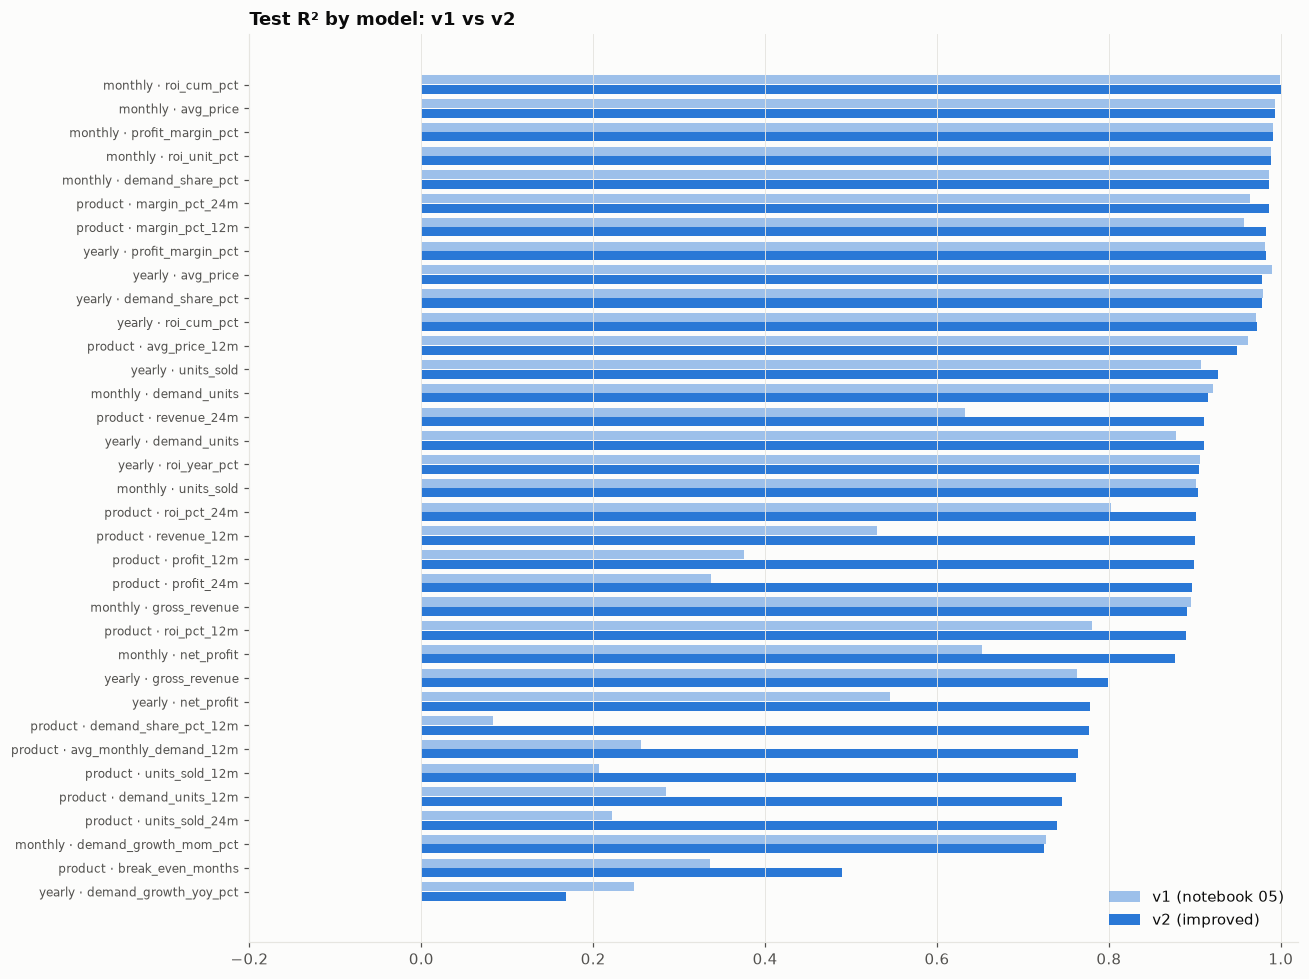

In [9]:
fig, ax = plt.subplots(figsize=(12, 9))
r = v2[v2.target != "never_breaks_even"].assign(label=lambda x: x.level + " · " + x.target).sort_values("test_R2")
yy = np.arange(len(r))
ax.barh(yy + .2, r.v1_R2.clip(lower=-.2), height=.38, color=SERIES[0], alpha=.45, label="v1 (notebook 05)")
ax.barh(yy - .2, r.test_R2.clip(lower=-.2), height=.38, color=SERIES[0], label="v2 (improved)")
ax.set_yticks(yy, r.label, fontsize=8); ax.set(title="Test R² by model: v1 vs v2", xlim=(-.2, 1.02)); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
fig.tight_layout(); savefig(fig, "06_v1_vs_v2_r2")

## 7. Final retrain on ALL data (train + test) → `models/final/`

In [10]:
m_all = pd.concat([m_train, m_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)
p_all, _, encoders = add_product_features(pd.concat([p_train, p_test], ignore_index=True), [])
ALL = {"monthly": m_all, "yearly": y_all, "product": p_all}
registry = []
for cfg in C:
    d = ALL[cfg["level"]]; d = d[d[cfg["target"]].notna()]
    m = None if cfg.get("composite") else new_model(cfg, cfg["trees"]).fit(d[cfg["features"]], target_space(d, cfg)[0])
    out = MODELS / "final" / cfg["level"]; out.mkdir(parents=True, exist_ok=True)
    bundle = {"model": m, "features": cfg["features"], "target": cfg["target"], "level": cfg["level"], "transform": cfg.get("tf"),
              "base_col": cfg.get("base_col"), "loss": cfg.get("loss", "squared_error"), "classifier": bool(cfg.get("classifier")),
              "composite": cfg.get("composite"), "trees": cfg["trees"], "trained_rows": len(d),
              "algorithm": "composite: revenue × margin / 100" if m is None else type(m).__name__}
    joblib.dump(bundle, out / f"{cfg['target']}.joblib")
    t = v2[(v2.level == cfg["level"]) & (v2.target == cfg["target"])].iloc[0]
    registry.append({k: bundle[k] for k in ["level", "target", "algorithm", "transform", "base_col", "loss", "trees", "trained_rows"]}
                    | {"n_features": len(cfg["features"]), "test_R2": t.get("test_R2"), "test_MAE": t.get("test_MAE"), "test_AUC": t.get("test_AUC"),
                       "beats_baseline": t.get("beats_baseline"), "path": f"models/final/{cfg['level']}/{cfg['target']}.joblib"})
joblib.dump({"encoders": encoders, "k_smooth": K_SMOOTH, "specs": TE_SPECS}, MODELS / "final" / "product_track_record_encoders.joblib")
reg = pd.DataFrame(registry); reg.to_csv(MODELS / "final" / "model_registry.csv", index=False)
print(f"Saved {len(reg)} final models + encoders to models/final/")
reg

Saved 36 final models + encoders to models/final/


,level,target,algorithm,transform,base_col,loss,trees,trained_rows,n_features,test_R2,test_MAE,test_AUC,beats_baseline,path
0,monthly,units_sold,HistGradientBoostingRegressor,log1p,NaN,squared_error,600,68299,110,0.904,633.828,NaN,1.000,models/final/monthly/units_sold.joblib
1,monthly,demand_units,HistGradientBoostingRegressor,log1p,NaN,squared_error,400,68299,110,0.916,591.707,NaN,1.000,models/final/monthly/demand_units.joblib
2,monthly,demand_share_pct,HistGradientBoostingRegressor,log1p,NaN,squared_error,500,68299,110,0.986,0.154,NaN,1.000,models/final/monthly/demand_share_pct.joblib
3,monthly,demand_growth_mom_pct,HistGradientBoostingRegressor,none,NaN,squared_error,400,67494,110,0.724,17.386,NaN,1.000,models/final/monthly/demand_growth_mom_pct.joblib
4,monthly,avg_price,HistGradientBoostingRegressor,log1p,NaN,squared_error,500,68299,104,0.993,3.523,NaN,1.000,models/final/monthly/avg_price.joblib
5,monthly,gross_revenue,HistGradientBoostingRegressor,log1p,NaN,squared_error,500,68299,110,0.890,"71,773.937",NaN,1.000,models/final/monthly/gross_revenue.joblib
6,monthly,profit_margin_pct,HistGradientBoostingRegressor,none,NaN,squared_error,1500,68283,110,0.991,1.774,NaN,1.000,models/final/monthly/profit_margin_pct.joblib
7,monthly,roi_unit_pct,HistGradientBoostingRegressor,none,NaN,squared_error,1400,68283,110,0.989,5.915,NaN,NaN,models/final/monthly/roi_unit_pct.joblib
8,monthly,net_profit,HistGradientBoostingRegressor,none,NaN,absolute_error,1500,68299,110,0.877,"22,564.707",NaN,1.000,models/final/monthly/net_profit.joblib
9,monthly,roi_cum_pct,HistGradientBoostingRegressor,none,roi_cum_pct_lag1,squared_error,1500,68299,110,1.000,4.768,NaN,1.000,models/final/monthly/roi_cum_pct.joblib


In [11]:
# Smoke test: reload final models and score one product end-to-end
row = p_all[p_all.product_id == p_test.product_id.iloc[0]]
def load_cfg(level, t):
    b = joblib.load(MODELS / "final" / level / f"{t}.joblib")
    return {"level": level, "target": t, "classifier": b["classifier"], "tf": b["transform"], "base_col": b["base_col"],
            "features": b["features"], "composite": b["composite"]}, b["model"]
final_store = {("product", t): load_cfg("product", t) for t in ["revenue_12m", "margin_pct_12m"]}
res = {}
for t in ["units_sold_12m", "revenue_12m", "profit_12m", "margin_pct_12m", "roi_pct_12m", "break_even_months", "never_breaks_even"]:
    cfg, m = load_cfg("product", t)
    res[t] = (round(float(predict(cfg, m, row, final_store)[0]), 2), "actual", row[t].iloc[0])
print(row.product_name.iloc[0][:80]); res

Pigeon by Stovekraft Amaze Plus Electric Kettle (14289) with Stainless Steel Bod


{'units_sold_12m': (445058.85, 'actual', np.float64(444364.0)),
 'revenue_12m': (6448742.48, 'actual', np.float64(6450044.02)),
 'profit_12m': (-515806.41, 'actual', np.float64(-514661.88)),
 'margin_pct_12m': (-8.0, 'actual', np.float64(-7.979)),
 'roi_pct_12m': (-227.18, 'actual', np.float64(-145.009)),
 'break_even_months': (87.51, 'actual', np.float64(91.0)),
 'never_breaks_even': (0.02, 'actual', np.int64(0))}

## Summary
- Fixes were chosen with validation data only. The test set was used once (section 6).
- `reports/metrics/model_metrics_v2.csv` holds the final honest test scores, compared with v1 and the baselines.
- `models/final/` holds 36 models retrained on all data, `model_registry.csv`, and the product track-record encoders.
- **Inference for delta models:** prediction = model output + `base_col` (e.g. last month's cumulative ROI). Stored in each bundle.
- **Composite models** (`profit_12m`, `profit_24m`) have no own model: prediction = revenue model × margin model / 100.
- **Product models need market-traction inputs:** the listing's review count and months on market, or those of a comparable competitor for a new idea.